# 量价因子搜索: 选择期冻结一个候选

这里想看一个具体问题: 六个方向已经固定的量价候选里, 谁在 2021-2022 年的平均 Rank IC 最高, 它在 2023 年以后是否还不差于 12-1 动量

## 先固定计算口径

- 数据: 本仓库 `data/quanttoolkit.db` 的 prices 与 universe, 只读, 不使用工具箱默认数据库路径
- 基准: $MOM_{63}=\ln(P_t/P_{t-63})$, 对应 `base_momfactor(window=63, skip=0)`
- 基准: $MOM_{231,21}=\ln(P_{t-21}/P_{t-252})$, 对应 `base_momfactor(window=231, skip=21)`
- 低波动: 63 日对数收益的样本标准差取负, 对应 `-base_logvolfactor(window=63)`
- 主标签: $R_t^{(21)}=P_{t+22}/P_{t+1}-1$, 对应 `future_returns(n_periods=21, gap=1)`
- 另外五个候选: 日内强度, 隔夜反转, 收盘位置, 量价背离, 路径平滑, 工具箱没有现成函数, 公式见实验脚本
- 选择规则: 只看选择期的平均 Rank IC, 不搜索窗口, 不改符号, 先冻结再看检查期和留出期
- 共同样本: 八个因子和标签同时有效, 最近 64 条记录成交量大于 0, 至少 252 条历史价格变化, 当天至少 100 只股票

## 分析步骤

1. 数据读取与时间对齐
2. 因子与标签
3. 共同样本覆盖
4. 发现期和选择期, 冻结一个候选
5. 每日 Rank IC 与 ICIR
6. 重叠标签的自相关, Newey-West 与协议中的区块自助法
7. 持有期, 行业中性和分段稳健性
8. 分位组合
9. 追加查看隔夜反转
10. 结论


## 1 数据读取与时间对齐

prices 以 (date, ticker) 为主键, 入库时已补齐每只股票首尾之间的交易日缺口
补齐日的价格沿用前一条记录, volume = 0
隔夜和日内因子还需要 open, high, low, close, 动量和标签只用 adj_close
名单是建库时的当前成员, 不是历史成分股


In [1]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from loguru import logger

from quanttoolkit.db.connection import get_duckdb
from quanttoolkit.factors.logvol_base import base_logvolfactor
from quanttoolkit.factors.mom_base import base_momfactor
from quanttoolkit.factors.neutral import neutralize_by_industry
from quanttoolkit.metrics import ic_summary, rank_ic
from quanttoolkit.panel.returns import future_returns
from quanttoolkit.panel.transfer import to_date_ticker_frame
from quanttoolkit.tracelog import configure_log

from experiment import (
    BENCHMARKS,
    CANDIDATES,
    HORIZON,
    MIN_NAMES,
    PERIODS,
    choose_factor,
    daily_rank_ic,
    forward_quintiles,
    make_factors,
    paired_bootstrap,
    period_dates,
    sample_mask,
    second_look_choice,
)

logger.remove()
logger.add(sys.stderr, level="WARNING")

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 200,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

HERE = Path.cwd().resolve()
ROOT = HERE.parents[1]
DB_PATH = ROOT / "data" / "quanttoolkit.db"
FIG_DIR = HERE / "figures"
OUT_DIR = HERE / "outputs"
FIG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)
configure_log(HERE / "trace.log")
print(DB_PATH)


/workspace/data/quanttoolkit.db


In [2]:
with get_duckdb(path=DB_PATH, read_only=True) as connection:
    universe = connection.execute(
        "SELECT ticker, name, sub_industry FROM universe ORDER BY ticker"
    ).df()
    raw = connection.execute(
        "SELECT date, ticker, open, high, low, close, adj_close, volume "
        "FROM prices ORDER BY date, ticker"
    ).df()

industry = universe.drop_duplicates("ticker").set_index("ticker")["sub_industry"]
prices = to_date_ticker_frame(df=raw)
dates = prices.index.get_level_values("date")

print("成员数", len(universe), "子行业数", industry.nunique())
print(
    "行情行数",
    len(prices),
    "股票数",
    prices.index.get_level_values("ticker").nunique(),
)
print("日期范围", dates.min().date(), "至", dates.max().date())
print("交易日数", dates.nunique())
print("adj_close 缺失", int(prices["adj_close"].isna().sum()))
print("成交量为 0 的补齐日", int((prices["volume"] == 0).sum()))
display(prices[["adj_close", "volume"]].head())


成员数 503 子行业数 126
行情行数 1321702 股票数 503
日期范围 2016-01-04 至 2026-10-27
交易日数 2720
adj_close 缺失 0
成交量为 0 的补齐日 2743


adj_close       volume
date       ticker                        
2016-01-04 A       37.356041    3287300.0
           AAPL    23.688679  270597600.0
           ABBV    36.906364   10308400.0
           ABT     34.697048   12227500.0
           ACGL    21.823122    1220700.0

## 2 因子与标签

动量在 $t$ 日收盘后得到, 只使用截至 $t$ 的价格
`base_momfactor` 和 `base_logvolfactor` 按每只证券自己的交易记录滚动
低波动在工具箱标准差上取负, 过去越平稳, 因子越大
标签用下一笔记录的收盘价入场, 再持有 21 笔记录
成交量为 0 的补齐日不进入隔夜, 日内, 收盘位置, 量价和路径平滑


In [3]:
mom_63 = base_momfactor(prices, window=63)
mom_12_1 = base_momfactor(prices, window=231, skip=21)
low_vol = -base_logvolfactor(prices, window=63)
label = future_returns(df=prices, n_periods=HORIZON, gap=1)
factors = make_factors(prices)

gap = pd.DataFrame(
    {
        "mom_63": factors["mom_63"] - mom_63,
        "mom_231_skip_21": factors["mom_231_skip_21"] - mom_12_1,
        "low_volatility_63": factors["low_volatility_63"] - low_vol,
    }
)
print("与工具箱动量, 低波动的最大绝对差")
print(gap.abs().max().round(12))
print("标签", label.name)
print("mom_63 首个有效日", mom_63.first_valid_index()[0].date())
print("12-1 动量首个有效日", mom_12_1.first_valid_index()[0].date())
print("标签首个有效日", label.first_valid_index()[0].date())
display(factors.dropna(how="all").head())


与工具箱动量, 低波动的最大绝对差
mom_63               0.0
mom_231_skip_21      0.0
low_volatility_63    0.0
dtype: float64
标签 forward_return_21_gap_1
mom_63 首个有效日 2016-04-05
12-1 动量首个有效日 2017-01-03
标签首个有效日 2016-01-04


mom_63  mom_231_skip_21  intraday_strength_63  overnight_reversal_63  closing_pressure_21  price_volume_divergence_63  low_volatility_63  smooth_momentum_63
date       ticker                                                                                                                                                              
2016-02-02 A          NaN              NaN                   NaN                    NaN            -0.136496                         NaN                NaN                 NaN
           AAPL       NaN              NaN                   NaN                    NaN            -0.009144                         NaN                NaN                 NaN
           ABBV       NaN              NaN                   NaN                    NaN             0.078011                         NaN                NaN                 NaN
           ABT        NaN              NaN                   NaN                    NaN            -0.054439                         NaN                NaN                 NaN
           ACGL       NaN              NaN                   NaN                    NaN             0.041425                         NaN                NaN                 NaN

## 3 共同样本覆盖: 哪些股票能同时进入比较

八个因子使用同一张日期和证券掩码, 不给某个因子单独换一组更好算的样本
universe 是最近一次抓取的当前成员名单, 不是历史成分股名单
下面的有效样本还要求标签进出场两天成交量大于 0


In [4]:
mask = sample_mask(prices, factors, label)
price_dates = prices.index.get_level_values("date")
price_tickers = prices.index.get_level_values("ticker")


def first_valid_date(flag):
    valid = flag[flag.fillna(False)]
    if valid.empty:
        return pd.Series(dtype="datetime64[ns]")
    return (
        pd.Series(
            valid.index.get_level_values("date"),
            index=valid.index.get_level_values("ticker"),
        )
        .groupby(level=0)
        .min()
    )


coverage = pd.DataFrame(index=pd.Index(universe["ticker"], name="ticker"))
coverage["name"] = universe.set_index("ticker")["name"]
coverage["sub_industry"] = industry.reindex(coverage.index)
coverage["n_prices"] = prices.groupby(level="ticker").size()
coverage["first_price"] = (
    pd.Series(price_dates, index=price_tickers).groupby(level=0).min()
)
coverage["last_price"] = (
    pd.Series(price_dates, index=price_tickers).groupby(level=0).max()
)
coverage["first_sample"] = first_valid_date(mask)
coverage["n_valid"] = (
    mask.groupby(level="ticker").sum().reindex(coverage.index, fill_value=0).astype(int)
)

daily_n = mask.groupby(level="date").sum()
daily_n = daily_n[daily_n > 0]
n_all = len(coverage)
n_price = int(coverage["n_prices"].gt(0).sum())
n_sample = int(coverage["first_sample"].notna().sum())
print(
    f"当前成员 {n_all}, 有价格 {n_price}, 至少一天进入共同样本 {n_sample}"
)
print(
    f"每日截面: 均值 {daily_n.mean():.1f}, 最小 {daily_n.min()}, 最大 {daily_n.max()}, 交易日 {len(daily_n)}"
)
print(
    f"首日截面 {daily_n.index[0].date()} 有 {int(daily_n.iloc[0])} 只, "
    f"末日截面 {daily_n.index[-1].date()} 有 {int(daily_n.iloc[-1])} 只"
)
print("没有任何共同样本的股票")
display(
    coverage.loc[coverage["first_sample"].isna(), ["name", "sub_industry", "n_prices", "first_price"]]
)
coverage.to_csv(OUT_DIR / "coverage_by_ticker.csv")


当前成员 503, 有价格 503, 至少一天进入共同样本 499
每日截面: 均值 482.2, 最小 460, 最大 499, 交易日 2446
首日截面 2017-01-03 有 461 只, 末日截面 2026-09-25 有 498 只
没有任何共同样本的股票


,name,sub_industry,n_prices,first_price
ticker,,,,
FDXF,FedEx Freight,Cargo Ground Transportation,107,2026-05-27
HONA,Honeywell Aerospace,Aerospace & Defense,94,2026-06-15
Q,Qnity Electronics,Semiconductor Materials & Equipment,252,2025-10-27
VYLR,Vylor,Agricultural Products & Services,19,2026-10-01


In [5]:
late = coverage[coverage["first_price"] > pd.Timestamp("2016-01-04")].sort_values(
    "first_price"
)
print("首条价格晚于 2016-01-04 的成员", len(late))
display(late[["name", "sub_industry", "first_price", "first_sample", "n_valid"]].head(10))
late.to_csv(OUT_DIR / "late_listings.csv")


首条价格晚于 2016-01-04 的成员 39


,name,sub_industry,first_price,first_sample,n_valid
ticker,,,,,
TWLO,Twilio,Systems Software,2016-06-23,2017-06-23,2327
FTV,Fortive,Industrial Machinery & Supplies & Components,2016-07-05,2017-07-05,2320
DELL,Dell Technologies,"Technology Hardware, Storage & Peripherals",2016-08-17,2017-08-17,2289
VST,Vistra Corp.,Electric Utilities,2016-10-05,2017-10-05,2255
HWM,Howmet Aerospace,Aerospace & Defense,2016-11-01,2017-11-01,2236
INVH,Invitation Homes,Single-Family Residential REITs,2017-02-01,2018-02-01,2174
CVNA,Carvana,Automotive Retail,2017-04-28,2018-04-30,2114
IR,Ingersoll Rand,Industrial Machinery & Supplies & Components,2017-05-12,2018-05-14,2104
VICI,Vici Properties,Hotel & Resort REITs,2018-01-02,2019-01-03,1943


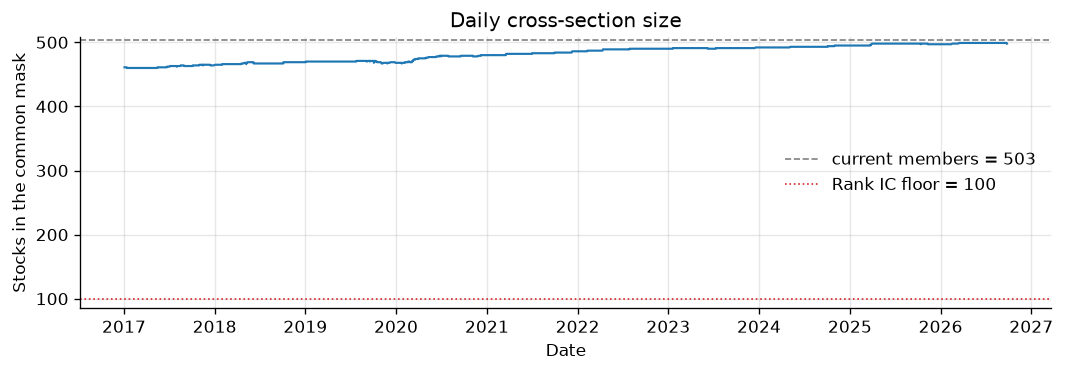

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(daily_n.index, daily_n.values, lw=1.3, color="C0")
ax.axhline(n_all, color="gray", ls="--", lw=1, label=f"current members = {n_all}")
ax.axhline(MIN_NAMES, color="C3", ls=":", lw=1, label=f"Rank IC floor = {MIN_NAMES}")
ax.set_ylim(min(daily_n.min() - 15, MIN_NAMES - 15), n_all + 5)
ax.set_xlabel("Date")
ax.set_ylabel("Stocks in the common mask")
ax.set_title("Daily cross-section size")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_coverage.png", bbox_inches="tight")
plt.show()


## 4 发现期和选择期, 先冻结

发现期是 2017-01-01 至 2020-12-31, 选择期是 2021-01-01 至 2022-12-31
这一格只汇总这两个区间
标签退出日越过区间终点的信号日会去掉
Rank IC 用 `rank_ic`, 当天因子和比较值都非空的股票少于 100 只时记为缺失, 五分位使用同一门槛


mom_63 的 Rank IC 与工具箱最大绝对差 0.0


period,discovery,selection,days
factor,,,
mom_63,-0.006298,-0.016432,481
mom_231_skip_21,0.001767,-0.007176,481
intraday_strength_63,0.003569,-0.007233,481
overnight_reversal_63,0.021127,0.020234,481
closing_pressure_21,-0.015465,-0.015414,481
price_volume_divergence_63,0.011297,0.007215,481
low_volatility_63,-0.028328,0.035793,481
smooth_momentum_63,-0.001624,-0.010223,481


FROZEN low_volatility_63


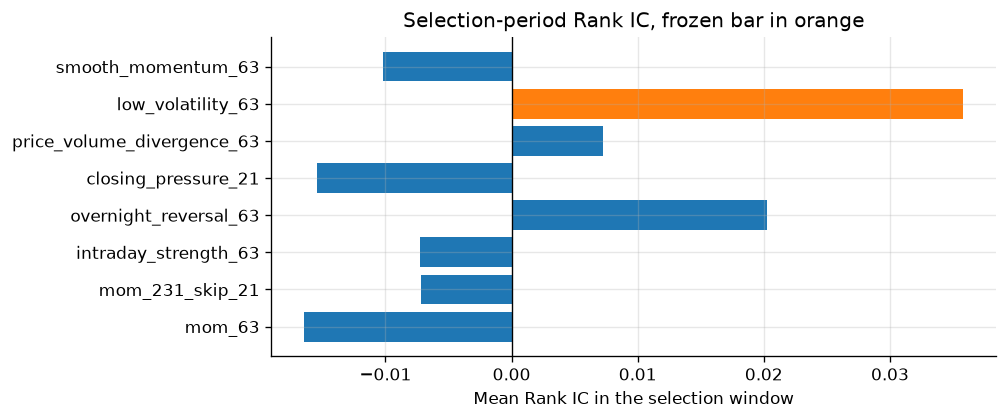

In [7]:
scores = pd.DataFrame(
    {
        name: daily_rank_ic(factors[name], label, mask, MIN_NAMES)
        for name in list(BENCHMARKS) + list(CANDIDATES)
    }
)
toolkit_ic = rank_ic(
    factor=factors["mom_63"].where(mask),
    forward_return=label.where(mask),
)
counts = mask.groupby(level="date").sum()
paired = pd.concat(
    [toolkit_ic.rename("toolkit"), scores["mom_63"].rename("study")],
    axis=1,
).dropna()
paired = paired.loc[counts.reindex(paired.index) >= MIN_NAMES]
print("mom_63 的 Rank IC 与工具箱最大绝对差", float((paired["toolkit"] - paired["study"]).abs().max()))

rows = []
for period in ("discovery", "selection"):
    kept = period_dates(scores.index, period, HORIZON)
    for name in scores.columns:
        part = scores.loc[scores.index.isin(kept), name].dropna()
        rows.append(
            {
                "factor": name,
                "period": period,
                "rank_ic": part.mean(),
                "days": len(part),
            }
        )
selection = pd.DataFrame(rows)
order = list(BENCHMARKS) + list(CANDIDATES)
view = selection.pivot(index="factor", columns="period", values="rank_ic").reindex(order)
view["days"] = (
    selection.loc[selection["period"] == "selection"]
    .set_index("factor")
    .reindex(order)["days"]
)
display(view.round(6))
chosen = choose_factor(selection)
print("FROZEN", chosen)
selection.to_csv(OUT_DIR / "selection.csv", index=False)

fig, ax = plt.subplots(figsize=(8.5, 3.6))
pick = selection.loc[selection["period"] == "selection"].set_index("factor").reindex(order)
colors = ["C1" if name == chosen else "C0" for name in pick.index]
ax.barh(pick.index, pick["rank_ic"], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Mean Rank IC in the selection window")
ax.set_title("Selection-period Rank IC, frozen bar in orange")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_selection.png", bbox_inches="tight")
plt.show()


## 5 每日 Rank IC 与 ICIR

冻结已经完成, 这里才看检查期 2023-2024 和 2025 年以后的留出期
$ICIR=\overline{IC}/s(IC)$, 标准差使用 ddof=1, 不做年化, 由 `ic_summary` 计算
图里的滚动均值和分年均值使用 2017 年以后全部完整标签, 不另做区间边界剔除


In [8]:
def period_table(score_frame, names, horizon=HORIZON):
    rows = []
    for period in PERIODS:
        kept = period_dates(score_frame.index, period, horizon)
        for name in names:
            part = score_frame.loc[score_frame.index.isin(kept), name].dropna()
            stats = ic_summary(ic=part)
            rows.append(
                {
                    "factor": name,
                    "period": period,
                    "n_days": len(part),
                    "first": None if part.empty else str(part.index.min().date()),
                    "last": None if part.empty else str(part.index.max().date()),
                    "ic_mean": stats["ic_mean"],
                    "ic_std": stats["ic_std"],
                    "ic_ir": stats["ic_ir"],
                    "ic_pos": stats["ic_pos"],
                }
            )
    return pd.DataFrame(rows)


names = list(BENCHMARKS) + [chosen]
summary = period_table(scores, names)
display(summary.round(6))
summary.to_csv(OUT_DIR / "ic_summary.csv", index=False)
scores.loc[scores.index >= "2017-01-01", names].to_csv(OUT_DIR / "daily_rank_ic.csv")


,factor,period,n_days,first,last,ic_mean,ic_std,ic_ir,ic_pos
0,mom_63,discovery,985,2017-01-03,2020-11-30,-0.006298,0.185236,-0.034001,0.530964
1,mom_231_skip_21,discovery,985,2017-01-03,2020-11-30,0.001767,0.218133,0.008100,0.518782
2,low_volatility_63,discovery,985,2017-01-03,2020-11-30,-0.028328,0.227286,-0.124638,0.480203
3,mom_63,selection,481,2021-01-04,2022-11-29,-0.016432,0.213167,-0.077084,0.482328
4,mom_231_skip_21,selection,481,2021-01-04,2022-11-29,-0.007176,0.190813,-0.037606,0.528067
5,low_volatility_63,selection,481,2021-01-04,2022-11-29,0.035793,0.244958,0.146119,0.571726
6,mom_63,check,480,2023-01-03,2024-11-27,-0.017068,0.158646,-0.107584,0.487500
7,mom_231_skip_21,check,480,2023-01-03,2024-11-27,0.047634,0.175930,0.270756,0.631250
8,low_volatility_63,check,480,2023-01-03,2024-11-27,-0.046190,0.208479,-0.221558,0.445833
9,mom_63,holdout,434,2025-01-02,2026-09-25,-0.021346,0.197941,-0.107840,0.509217


,low_volatility_63,mom_231_skip_21,n_days
year,,,
2017,-0.0327,0.0216,251
2018,0.0342,0.0009,251
2019,-0.0465,-0.0046,252
2020,-0.0891,-0.0085,253
2021,0.0056,-0.0671,252
2022,0.0323,0.0239,251
2023,-0.0634,0.0241,250
2024,-0.0366,0.0776,252
2025,-0.0950,-0.0079,250


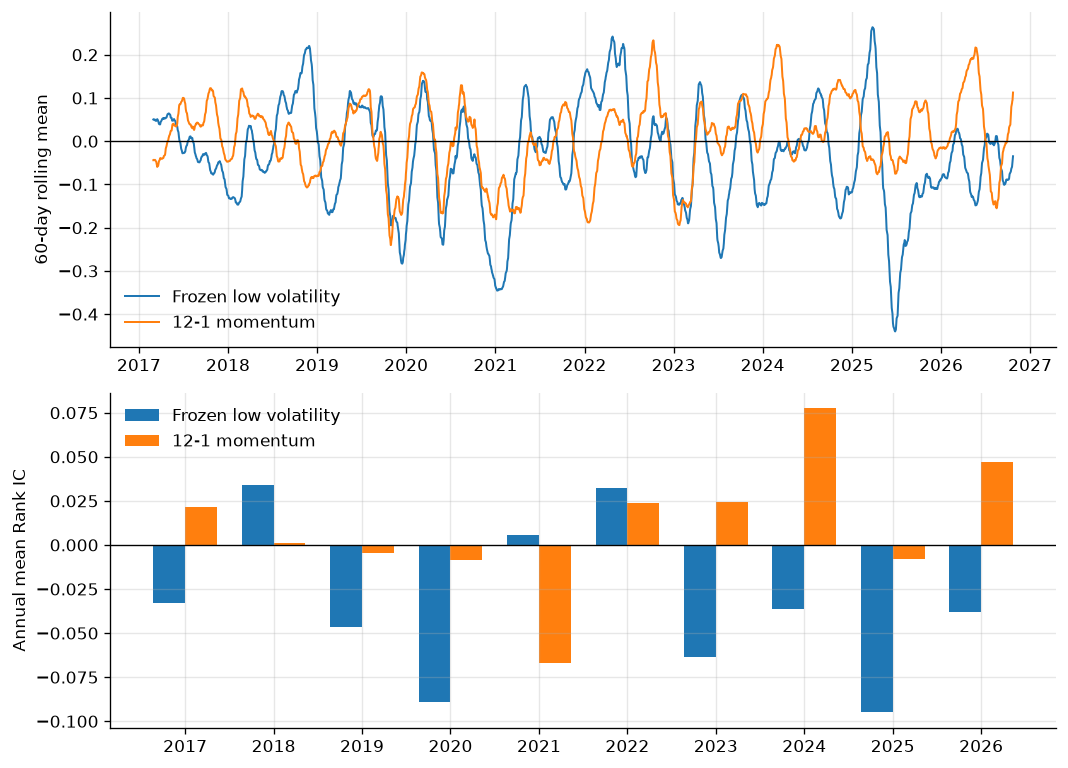

In [9]:
plot_names = [chosen, "mom_231_skip_21"]
plot_ic = scores.loc[scores.index >= "2017-01-01", plot_names]
yearly = plot_ic.groupby(plot_ic.index.year).mean()
yearly["n_days"] = plot_ic[chosen].groupby(plot_ic.index.year).count()
yearly.index.name = "year"
display(yearly.round(4))
yearly.to_csv(OUT_DIR / "yearly_ic.csv")

rolling = plot_ic.rolling(60, min_periods=40).mean()
fig, axes = plt.subplots(2, 1, figsize=(9, 6.5))
axes[0].plot(rolling.index, rolling[chosen], lw=1.2, label="Frozen low volatility")
axes[0].plot(
    rolling.index, rolling["mom_231_skip_21"], lw=1.2, label="12-1 momentum"
)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_ylabel("60-day rolling mean")
axes[0].legend(frameon=False)
years = np.arange(len(yearly))
axes[1].bar(years - 0.18, yearly[chosen], width=0.36, label="Frozen low volatility")
axes[1].bar(
    years + 0.18, yearly["mom_231_skip_21"], width=0.36, label="12-1 momentum"
)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xticks(years, yearly.index.astype(str))
axes[1].set_ylabel("Annual mean Rank IC")
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_ic.png", bbox_inches="tight")
plt.show()


## 6 重叠标签与 Newey-West

$t$ 日与 $t+1$ 日的 21 日标签共享 20 个日收益, 每日 Rank IC 会高度自相关
这里沿用参考笔记本的自相关和 Newey-West 均值检验, 最大滞后取 21
协议里预先写明的不确定性是另一件事: 冻结因子减去基准的日 Rank IC 差值, 63 日移动区块, 2000 次, 种子 18


In [10]:
daily_ic = scores.loc[scores.index >= "2017-01-01", names].dropna(how="any")
lags = [1, 2, 3, 5, 10, 15, 21, 42, 63]
acf = pd.DataFrame(
    {col: [daily_ic[col].autocorr(lag) for lag in lags] for col in daily_ic},
    index=lags,
)
acf.index.name = "lag"


def effective_sample(series, maxlags=21):
    values = series.dropna()
    weights = np.array([1 - k / (maxlags + 1) for k in range(1, maxlags + 1)])
    rhos = np.array([values.autocorr(k) for k in range(1, maxlags + 1)])
    return len(values) / (1 + 2 * np.sum(weights * rhos))


n_eff = pd.Series({col: effective_sample(daily_ic[col]) for col in daily_ic}, name="n_eff")
display(acf.round(3))
display(n_eff.round(1).to_frame())
acf.to_csv(OUT_DIR / "ic_acf.csv")


,mom_63,mom_231_skip_21,low_volatility_63
lag,,,
1,0.918,0.923,0.940
2,0.838,0.844,0.880
3,0.761,0.772,0.819
5,0.632,0.653,0.720
10,0.348,0.389,0.490
15,0.089,0.157,0.255
21,-0.161,-0.181,-0.040
42,-0.057,-0.111,-0.084
63,-0.117,0.004,-0.109


,n_eff
mom_63,213.6
mom_231_skip_21,202.4
low_volatility_63,179.3


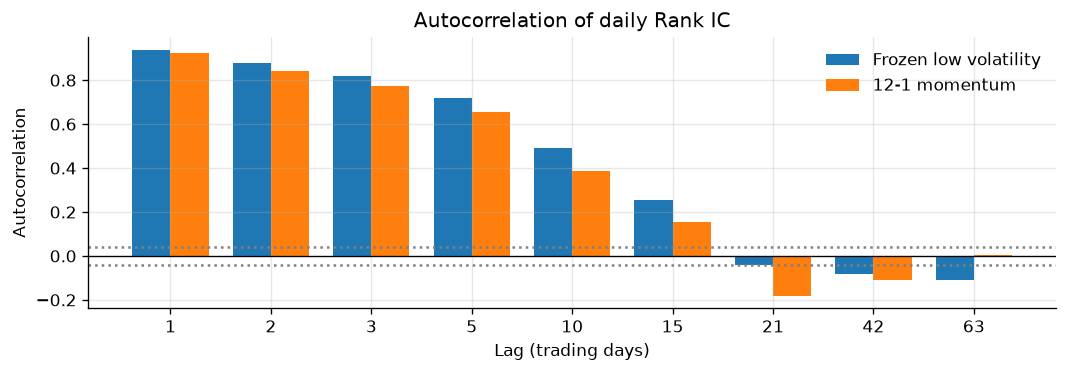

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.2))
positions = np.arange(len(lags))
width = 0.38
ax.bar(positions - width / 2, acf[chosen], width=width, label="Frozen low volatility")
ax.bar(
    positions + width / 2,
    acf["mom_231_skip_21"],
    width=width,
    label="12-1 momentum",
)
ax.axhline(0, color="black", lw=0.8)
band = 1.96 / np.sqrt(len(daily_ic))
ax.axhline(band, color="gray", ls=":")
ax.axhline(-band, color="gray", ls=":")
ax.set_xticks(positions, [str(lag) for lag in lags])
ax.set_xlabel("Lag (trading days)")
ax.set_ylabel("Autocorrelation")
ax.set_title("Autocorrelation of daily Rank IC")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_acf.png", bbox_inches="tight")
plt.show()


In [12]:
def newey_west_mean(series, maxlags=21):
    values = series.dropna().to_numpy()
    result = sm.OLS(values, np.ones((len(values), 1))).fit(
        cov_type="HAC", cov_kwds={"maxlags": maxlags}, use_t=False
    )
    low, high = result.conf_int(alpha=0.05)[0]
    return pd.Series(
        {
            "n": len(values),
            "mean": result.params[0],
            "nw_se": result.bse[0],
            "z": result.tvalues[0],
            "p_value": result.pvalues[0],
            "ci_low": low,
            "ci_high": high,
        }
    )


nw = pd.DataFrame(
    {col: newey_west_mean(daily_ic[col], maxlags=21) for col in daily_ic}
).T
nw["n_eff"] = n_eff
nw["se_naive"] = daily_ic.std(ddof=1) / np.sqrt(daily_ic.notna().sum())
nw["se_ratio"] = nw["nw_se"] / nw["se_naive"]
display(nw.round(6))
nw.to_csv(OUT_DIR / "ic_newey_west.csv")

diff_rows = []
for period in ("check", "holdout"):
    kept = period_dates(scores.index, period, HORIZON)
    for baseline in BENCHMARKS:
        diff = (scores[chosen] - scores[baseline]).loc[scores.index.isin(kept)].dropna()
        low, high = paired_bootstrap(diff)
        diff_rows.append(
            {
                "period": period,
                "baseline": baseline,
                "mean_ic_difference": diff.mean(),
                "ci95_low": low,
                "ci95_high": high,
                "days": len(diff),
            }
        )
uncertainty = pd.DataFrame(diff_rows)
print("协议中的配对区块自助法")
display(uncertainty.round(6))
uncertainty.to_csv(OUT_DIR / "paired_uncertainty.csv", index=False)


,n,mean,nw_se,z,p_value,ci_low,ci_high,n_eff,se_naive,se_ratio
mom_63,2446.0,-0.011567,0.012896,-0.896987,0.369726,-0.036842,0.013708,213.599453,0.003813,3.381879
mom_231_skip_21,2446.0,0.009692,0.014270,0.679192,0.497016,-0.018277,0.037661,202.372593,0.004108,3.473999
low_volatility_63,2446.0,-0.032786,0.017560,-1.867051,0.061894,-0.067204,0.001632,179.337379,0.004759,3.689981


协议中的配对区块自助法


,period,baseline,mean_ic_difference,ci95_low,ci95_high,days
0,check,mom_63,-0.029122,-0.107518,0.047261,480
1,check,mom_231_skip_21,-0.093824,-0.165680,-0.017830,480
2,holdout,mom_63,-0.049534,-0.168680,0.078286,434
3,holdout,mom_231_skip_21,-0.086353,-0.202120,0.042776,434


## 7 稳健性检验

- 滞后阶数: Newey-West 最大滞后从 5 改到 126, 看冻结因子的均值检验会不会换结论
- 非重叠抽样: 每 21 个交易日取一天
- 持有期: 5 日和 63 日标签, 入场间隔仍是 1
- 行业: `neutralize_by_industry` 按子行业去掉当天均值, 因子和标签一起处理


In [13]:
lag_grid = [5, 10, 21, 42, 63, 126]
lag_z = pd.DataFrame(
    {
        col: {lag: newey_west_mean(daily_ic[col], maxlags=lag)["z"] for lag in lag_grid}
        for col in daily_ic
    }
)
lag_z.index.name = "maxlags"
display(lag_z.round(3))
lag_z.to_csv(OUT_DIR / "ic_newey_west_lag_sensitivity.csv")

non_overlap = daily_ic.iloc[::21]
non_overlap_rows = {}
for col in daily_ic:
    values = non_overlap[col].dropna()
    non_overlap_rows[col] = {
        "n": len(values),
        "mean": values.mean(),
        "z": values.mean() / (values.std(ddof=1) / np.sqrt(len(values))),
    }
non_overlap_table = pd.DataFrame(non_overlap_rows).T
print("每 21 个交易日抽样")
display(non_overlap_table.round(4))


,mom_63,mom_231_skip_21,low_volatility_63
maxlags,,,
5,-1.346,1.042,-2.991
10,-1.068,0.822,-2.328
21,-0.897,0.679,-1.867
42,-0.883,0.673,-1.720
63,-0.917,0.713,-1.744
126,-1.125,0.813,-1.908


每 21 个交易日抽样


,n,mean,z
mom_63,117.0,-0.0158,-0.8347
mom_231_skip_21,117.0,0.0149,0.7565
low_volatility_63,117.0,-0.0303,-1.3642


In [14]:
robust_rows = []
for horizon in (5, 21, 63):
    forward = future_returns(df=prices, n_periods=horizon, gap=1)
    horizon_mask = sample_mask(prices, factors, forward, horizon=horizon)
    for adjusted in (False, True):
        other = (
            neutralize_by_industry(forward.where(horizon_mask).to_frame("value"), industry)[
                "value"
            ]
            if adjusted
            else forward
        )
        for name in names:
            signal = (
                neutralize_by_industry(
                    factors[name].where(horizon_mask).to_frame("value"), industry
                )["value"]
                if adjusted
                else factors[name]
            )
            score = daily_rank_ic(signal, other, horizon_mask, MIN_NAMES)
            for period in ("check", "holdout"):
                part = score.loc[
                    score.index.isin(period_dates(score.index, period, horizon))
                ].dropna()
                robust_rows.append(
                    {
                        "factor": name,
                        "horizon": horizon,
                        "industry_demeaned": adjusted,
                        "period": period,
                        "rank_ic": part.mean(),
                        "days": len(part),
                    }
                )
robustness = pd.DataFrame(robust_rows)
display(
    robustness.pivot_table(
        index=["horizon", "industry_demeaned", "factor"],
        columns="period",
        values="rank_ic",
    ).round(4)
)
robustness.to_csv(OUT_DIR / "robustness.csv", index=False)


period                                        check  holdout
horizon industry_demeaned factor                            
5       False             low_volatility_63 -0.0281  -0.0369
                          mom_231_skip_21    0.0268   0.0228
                          mom_63            -0.0106  -0.0039
        True              low_volatility_63 -0.0302  -0.0228
                          mom_231_skip_21    0.0220   0.0207
                          mom_63             0.0004  -0.0049
21      False             low_volatility_63 -0.0462  -0.0709
                          mom_231_skip_21    0.0476   0.0155
                          mom_63            -0.0171  -0.0213
        True              low_volatility_63 -0.0547  -0.0429
                          mom_231_skip_21    0.0494   0.0196
                          mom_63            -0.0045  -0.0091
63      False             low_volatility_63 -0.0973  -0.1123
                          mom_231_skip_21    0.0804   0.0317
                          mom_63            -0.0274  -0.0287
        True              low_volatility_63 -0.1058  -0.0771
                          mom_231_skip_21    0.0941   0.0403
                          mom_63             0.0007   0.0024

## 8 分位组合

每天按因子的平均秩分成 5 组, Q1 最低, Q5 最高
表内是各组未来 21 日简单收益的截面均值, 再对交易日取平均
标签重叠, 这里不把价差复利成净值, 也不扣费用


quintile                          1       2       3       4       5
factor            period                                           
low_volatility_63 check      0.0323  0.0169  0.0160  0.0112  0.0100
                  discovery  0.0250  0.0159  0.0150  0.0131  0.0127
                  holdout    0.0355  0.0135  0.0094  0.0047  0.0039
                  selection  0.0085  0.0059  0.0093  0.0086  0.0099
mom_231_skip_21   check      0.0176  0.0119  0.0134  0.0164  0.0269
                  discovery  0.0192  0.0154  0.0148  0.0143  0.0179
                  holdout    0.0122  0.0087  0.0101  0.0116  0.0242
                  selection  0.0075  0.0090  0.0108  0.0075  0.0075
mom_63            check      0.0208  0.0173  0.0158  0.0151  0.0175
                  discovery  0.0202  0.0153  0.0146  0.0149  0.0166
                  holdout    0.0168  0.0122  0.0118  0.0087  0.0174
                  selection  0.0092  0.0092  0.0076  0.0085  0.0079

,Low volatility,12-1 momentum
Q1,3.229,1.764
Q2,1.691,1.190
Q3,1.603,1.336
Q4,1.117,1.643
Q5,0.999,2.692


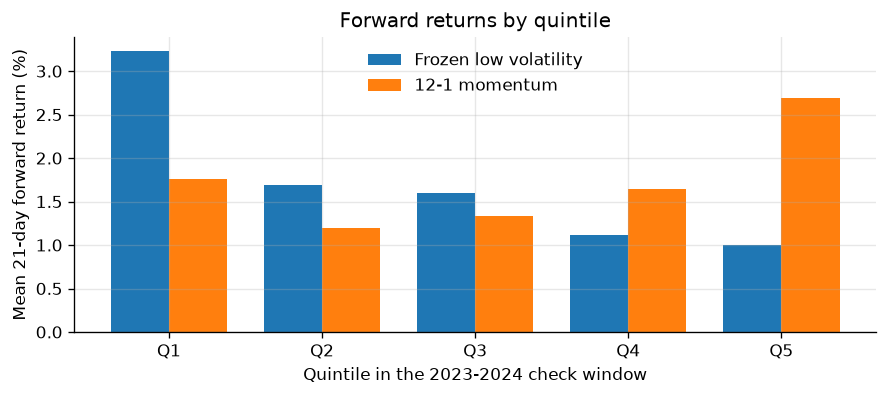

In [15]:
quintile_rows = []
for period in PERIODS:
    kept = period_dates(scores.index, period, HORIZON)
    for name in names:
        daily_q = forward_quintiles(factors[name], label, mask)
        daily_q = daily_q.loc[daily_q.index.isin(kept)]
        for group, value in daily_q.mean().items():
            quintile_rows.append(
                {
                    "factor": name,
                    "period": period,
                    "quintile": int(group),
                    "mean_forward_return": value,
                }
            )
quintiles = pd.DataFrame(quintile_rows)
display(
    quintiles.pivot_table(
        index=["factor", "period"], columns="quintile", values="mean_forward_return"
    ).round(4)
)
quintiles.to_csv(OUT_DIR / "quintile_returns.csv", index=False)

check_dates = period_dates(scores.index, "check", HORIZON)
q_plot = {}
for name, title in ((chosen, "Low volatility"), ("mom_231_skip_21", "12-1 momentum")):
    daily_q = forward_quintiles(factors[name], label, mask)
    q_plot[title] = daily_q.loc[daily_q.index.isin(check_dates)].mean() * 100
quintile_table = pd.DataFrame(q_plot)
quintile_table.index = [f"Q{i}" for i in quintile_table.index]
display(quintile_table.round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
positions = np.arange(len(quintile_table))
width = 0.38
ax.bar(
    positions - width / 2,
    quintile_table["Low volatility"],
    width=width,
    label="Frozen low volatility",
)
ax.bar(
    positions + width / 2,
    quintile_table["12-1 momentum"],
    width=width,
    label="12-1 momentum",
)
ax.set_xticks(positions, quintile_table.index)
ax.set_xlabel("Quintile in the 2023-2024 check window")
ax.set_ylabel("Mean 21-day forward return (%)")
ax.set_title("Forward returns by quintile")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_quintile.png", bbox_inches="tight")
plt.show()


## 9 追加查看隔夜反转

首轮规则已经冻结低波动, 并且检查期和留出期都没有留下优势
追加规则只使用发现期和选择期: 两段 Rank IC 都为正的候选里, 取较小的那一段最高的一个
这个规则是在看到低波动走弱之后才启用的, 下面的检查期和留出期不能当成未被看过的确认
隔夜因子是过去 63 个隔夜对数收益之和再取负


追加规则选中 overnight_reversal_63


,factor,period,n_days,first,last,ic_mean,ic_std,ic_ir,ic_pos
0,mom_63,discovery,985,2017-01-03,2020-11-30,-0.006298,0.185236,-0.034001,0.530964
1,mom_231_skip_21,discovery,985,2017-01-03,2020-11-30,0.001767,0.218133,0.008100,0.518782
2,overnight_reversal_63,discovery,985,2017-01-03,2020-11-30,0.021127,0.131621,0.160515,0.556345
3,mom_63,selection,481,2021-01-04,2022-11-29,-0.016432,0.213167,-0.077084,0.482328
4,mom_231_skip_21,selection,481,2021-01-04,2022-11-29,-0.007176,0.190813,-0.037606,0.528067
5,overnight_reversal_63,selection,481,2021-01-04,2022-11-29,0.020234,0.163075,0.124078,0.598753
6,mom_63,check,480,2023-01-03,2024-11-27,-0.017068,0.158646,-0.107584,0.487500
7,mom_231_skip_21,check,480,2023-01-03,2024-11-27,0.047634,0.175930,0.270756,0.631250
8,overnight_reversal_63,check,480,2023-01-03,2024-11-27,-0.009282,0.133128,-0.069719,0.397917
9,mom_63,holdout,434,2025-01-02,2026-09-25,-0.021346,0.197941,-0.107840,0.509217


,period,baseline,mean_ic_difference,ci95_low,ci95_high,days
0,check,mom_63,0.007786,-0.065304,0.087379,480
1,check,mom_231_skip_21,-0.056916,-0.121648,0.000921,480
2,holdout,mom_63,0.074438,-0.062933,0.220114,434
3,holdout,mom_231_skip_21,0.037619,-0.095940,0.168504,434


隔夜反转年平均 Rank IC 高于 12-1 动量的年份 5 共 10


,mom_63,mom_231_skip_21,overnight_reversal_63
date,,,
2017,0.0275,0.0216,-0.0168
2018,-0.0106,0.0009,0.0476
2019,-0.0330,-0.0046,0.0465
2020,0.0093,-0.0085,-0.0049
2021,-0.0321,-0.0671,0.0421
2022,-0.0104,0.0239,0.0138
2023,-0.0498,0.0241,0.0143
2024,0.0231,0.0776,-0.0437
2025,-0.0083,-0.0079,0.0764


period                                            check  holdout
horizon industry_demeaned factor                                
5       False             mom_231_skip_21        0.0268   0.0228
                          mom_63                -0.0106  -0.0039
                          overnight_reversal_63 -0.0078   0.0268
        True              mom_231_skip_21        0.0220   0.0207
                          mom_63                 0.0004  -0.0049
                          overnight_reversal_63 -0.0048   0.0173
21      False             mom_231_skip_21        0.0476   0.0155
                          mom_63                -0.0171  -0.0213
                          overnight_reversal_63 -0.0093   0.0531
        True              mom_231_skip_21        0.0494   0.0196
                          mom_63                -0.0045  -0.0091
                          overnight_reversal_63 -0.0071   0.0259
63      False             mom_231_skip_21        0.0804   0.0317
                          mom_63                -0.0274  -0.0287
                          overnight_reversal_63  0.0422   0.0320
        True              mom_231_skip_21        0.0941   0.0403
                          mom_63                 0.0007   0.0024
                          overnight_reversal_63 -0.0170  -0.0006

,Overnight reversal,12-1 momentum
Q1,2.200,1.764
Q2,1.585,1.190
Q3,1.447,1.336
Q4,1.392,1.643
Q5,2.009,2.692


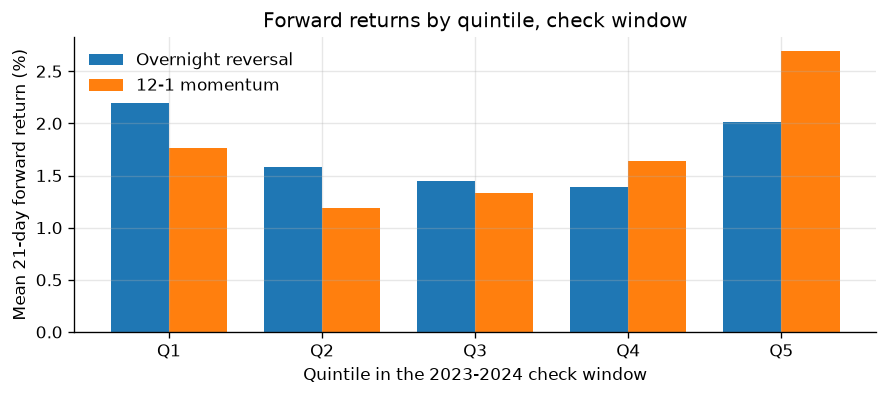

In [16]:
rule_choice = second_look_choice(selection)
print("追加规则选中", rule_choice)
overnight = "overnight_reversal_63"
follow_names = list(BENCHMARKS) + [overnight]
follow = period_table(scores, follow_names)
display(follow.round(6))
follow.to_csv(OUT_DIR / "overnight_ic_summary.csv", index=False)

overnight_diff = []
for period in ("check", "holdout"):
    kept = period_dates(scores.index, period, HORIZON)
    for baseline in BENCHMARKS:
        diff = (scores[overnight] - scores[baseline]).loc[scores.index.isin(kept)].dropna()
        low, high = paired_bootstrap(diff)
        overnight_diff.append(
            {
                "period": period,
                "baseline": baseline,
                "mean_ic_difference": diff.mean(),
                "ci95_low": low,
                "ci95_high": high,
                "days": len(diff),
            }
        )
overnight_uncertainty = pd.DataFrame(overnight_diff)
display(overnight_uncertainty.round(6))
overnight_uncertainty.to_csv(OUT_DIR / "overnight_paired_uncertainty.csv", index=False)

ov = scores.loc[scores.index >= "2017-01-01", follow_names]
yearly_ov = ov.groupby(ov.index.year).mean()
beat = int((yearly_ov[overnight] > yearly_ov["mom_231_skip_21"]).sum())
print("隔夜反转年平均 Rank IC 高于 12-1 动量的年份", beat, "共", len(yearly_ov))
display(yearly_ov.round(4))
yearly_ov.to_csv(OUT_DIR / "overnight_yearly_ic.csv")

extra = []
for horizon in (5, 21, 63):
    forward = future_returns(df=prices, n_periods=horizon, gap=1)
    horizon_mask = sample_mask(prices, factors, forward, horizon=horizon)
    for adjusted in (False, True):
        other = (
            neutralize_by_industry(forward.where(horizon_mask).to_frame("value"), industry)[
                "value"
            ]
            if adjusted
            else forward
        )
        signal = (
            neutralize_by_industry(
                factors[overnight].where(horizon_mask).to_frame("value"), industry
            )["value"]
            if adjusted
            else factors[overnight]
        )
        score = daily_rank_ic(signal, other, horizon_mask, MIN_NAMES)
        for period in ("check", "holdout"):
            part = score.loc[
                score.index.isin(period_dates(score.index, period, horizon))
            ].dropna()
            extra.append(
                {
                    "factor": overnight,
                    "horizon": horizon,
                    "industry_demeaned": adjusted,
                    "period": period,
                    "rank_ic": part.mean(),
                    "days": len(part),
                }
            )
overnight_robust = pd.concat(
    [robustness.loc[robustness["factor"].isin(BENCHMARKS)], pd.DataFrame(extra)],
    ignore_index=True,
)
display(
    overnight_robust.pivot_table(
        index=["horizon", "industry_demeaned", "factor"],
        columns="period",
        values="rank_ic",
    ).round(4)
)
overnight_robust.to_csv(OUT_DIR / "overnight_robustness.csv", index=False)

q_ov = {}
for name, title in ((overnight, "Overnight reversal"), ("mom_231_skip_21", "12-1 momentum")):
    daily_q = forward_quintiles(factors[name], label, mask)
    q_ov[title] = daily_q.loc[daily_q.index.isin(check_dates)].mean() * 100
q_ov = pd.DataFrame(q_ov)
q_ov.index = [f"Q{i}" for i in q_ov.index]
display(q_ov.round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
positions = np.arange(len(q_ov))
width = 0.38
ax.bar(positions - width / 2, q_ov["Overnight reversal"], width=width, label="Overnight reversal")
ax.bar(positions + width / 2, q_ov["12-1 momentum"], width=width, label="12-1 momentum")
ax.set_xticks(positions, q_ov.index)
ax.set_xlabel("Quintile in the 2023-2024 check window")
ax.set_ylabel("Mean 21-day forward return (%)")
ax.set_title("Forward returns by quintile, check window")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_quintile_overnight.png", bbox_inches="tight")
plt.show()

from contextlib import redirect_stdout
from io import StringIO

from quanttoolkit.tracelog import print_call_chain

with redirect_stdout(StringIO()):
    print_call_chain()


## 10 结论

1. 覆盖: 当前 503 只成员都有价格, 共同掩码下每日大约 469 到 498 只股票, 高于 100 只的计算门槛
2. 冻结: 选择期平均 Rank IC 最高的候选是低波动, 约为 0.0358, 发现期同一因子约为 -0.0283, 选择只使用了选择期
3. 之后的表现: 低波动在检查期约为 -0.0462, 12-1 动量约为 0.0476, 差值的 95% 区块区间约为 [-0.166, -0.018], 留出期低波动约为 -0.0709, 12-1 动量约为 0.0155, 差值区间跨过 0
4. 重叠标签: 2017 年以后日度 Rank IC 的一阶自相关约为 0.92 到 0.94, 朴素标准误大约偏小 3.4 到 3.7 倍. 低波动全样本 Newey-West 均值约为 -0.0328, 95% 区间仍跨过 0. 协议里的检查期比较是相对 12-1 动量的区块区间, 那段区间位于 0 以下
5. 稳健性: 5 日和 63 日标签上, 低波动在检查期和留出期仍为负, 子行业去均值之后也没有转正
6. 分位: 检查期里低波动的 Q1 未来收益高于 Q5, 12-1 动量则是 Q5 更高
7. 隔夜反转: 追加规则确实会选中它, 发现期和选择期的平均 Rank IC 约为 0.0211 和 0.0202, 检查期约为 -0.0093, 留出期约为 0.0531, 相对 12-1 动量的两段差值区间都跨过 0 或贴着 0, 10 个年份里只有一部分年份更高, 检查期五分位也不单调

这次运行留下的是一个公式清楚的研究候选, 还不能说隔夜反转已经不差于 12-1 动量
低波动按预先写好的规则被选中, 随后在检查期和留出期都没有保持选择期的正向 Rank IC

## 主要局限

- 股票池是 2026-10-28 建库时的当前成员, 行情从 2016-01-04 到 2026-10-27, 有存活和历史成员偏差
- 本机原来没有任务目录那份数据库, 这里用工具箱 `data_pipeline` 重新下载, 2017 至 2024 的结果与任务目录里的表接近, 留出期因行情多了几天而略长, 最后一条完整 21 日标签在 2026-09-25
- 发现期和选择期参与了挑因子, 检查期和留出期只评估冻结结果, 隔夜反转是事后追加
- 重叠的未来收益只作为诊断, 没有换成可交易净值, 也没有费用
- 区块区间没有预设不劣界值, 也没有校正多次查看
